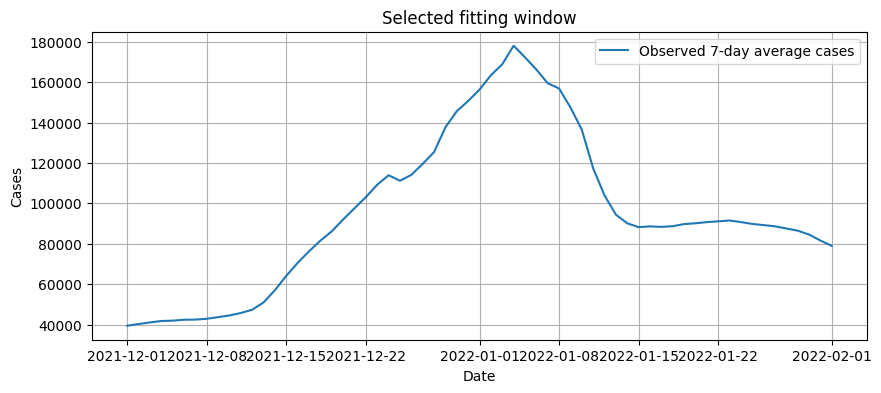

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# load data
df = pd.read_csv("../data/uk_final.csv")

df["date"] = pd.to_datetime(df["date"])

# choose one fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

data = df_fit["cases_7d"].values
t = np.arange(len(data))

# UK population
N = 67_000_000

# initial values
I0 = float(data[0])
R0 = 0.0
S0 = N - I0 - R0

plt.figure(figsize=(10, 4))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases")
plt.title("Selected fitting window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

In [3]:
def sir_model(t, y, beta, gamma, N):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_sir(beta, gamma, S0, I0, R0, N, t_eval):
    sol = solve_ivp(
        fun=lambda t, y: sir_model(t, y, beta, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45"
    )
    return sol.y

def loss_fn(params):
    beta, gamma = params
    if beta <= 0 or gamma <= 0:
        return 1e20
    S, I, R = simulate_sir(beta, gamma, S0, I0, R0, N, t)
    return np.mean((I - data) ** 2)

result = minimize(
    loss_fn,
    x0=[0.3, 0.1],
    bounds=[(1e-6, 2.0), (1e-6, 1.0)],
    method="L-BFGS-B"
)

beta_fit, gamma_fit = result.x
S_fit, I_fit, R_fit = simulate_sir(beta_fit, gamma_fit, S0, I0, R0, N, t)

mse = np.mean((I_fit - data) ** 2)
rmse = np.sqrt(mse)

print("beta =", beta_fit)
print("gamma =", gamma_fit)
print("R0 =", beta_fit / gamma_fit)
print("MSE =", mse)
print("RMSE =", rmse)

beta = 1.0562100021597933
gamma = 1.0
R0 = 1.0562100021597933
MSE = 390458418.5926781
RMSE = 19760.020713366626


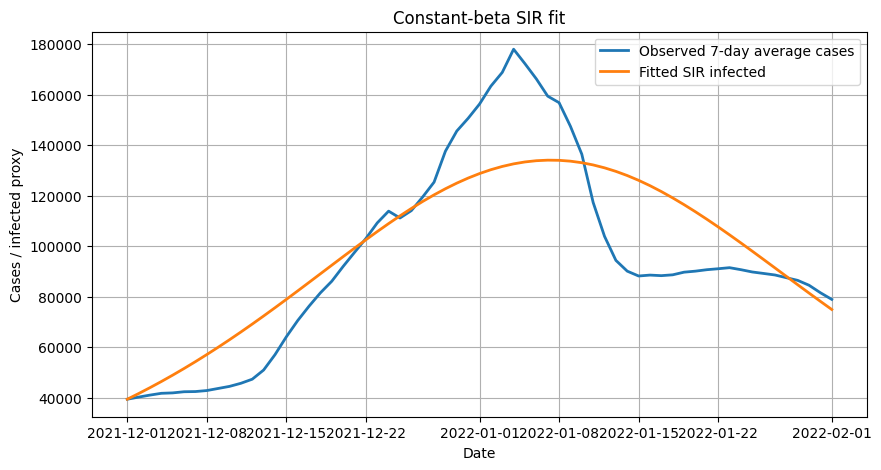

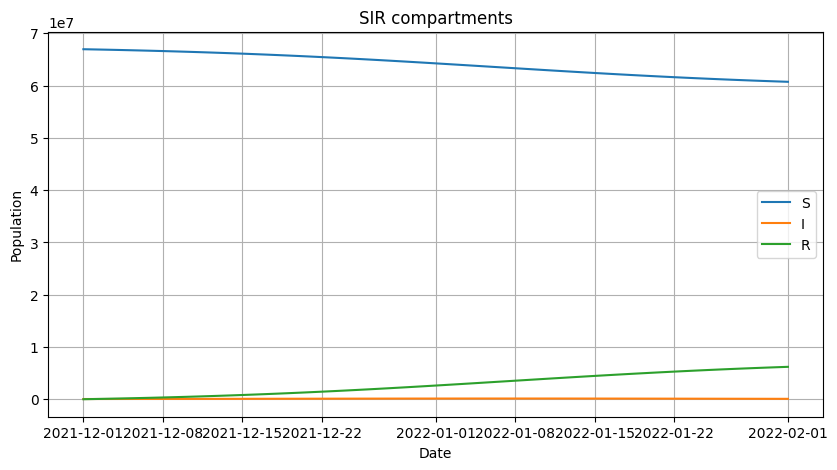

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases", linewidth=2)
plt.plot(df_fit["date"], I_fit, label="Fitted SIR infected", linewidth=2)
plt.title("Constant-beta SIR fit")
plt.xlabel("Date")
plt.ylabel("Cases / infected proxy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(df_fit["date"], S_fit, label="S")
plt.plot(df_fit["date"], I_fit, label="I")
plt.plot(df_fit["date"], R_fit, label="R")
plt.title("SIR compartments")
plt.xlabel("Date")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()